# Differential equations 8: Heat, waves and potentials

*Learning path: differential equations, part 8 of 8.* [Index](README.md) · Previous: [Fourier series](07-fourier-series.ipynb)

Heat spreading through a metal rod, a guitar string vibrating, the steady temperature of a plate: each depends on
position **and** time (or on two positions), so it obeys a **partial** differential equation. The three classics are

$$u_t = k\,u_{xx}\ \text{(heat)}, \qquad u_{tt} = c^2u_{xx}\ \text{(wave)}, \qquad u_{xx} + u_{yy} = 0\ \text{(Laplace)}.$$

One method, **separation of variables**, solves all three on simple shapes. It turns a PDE into ordinary differential
equations from lesson 3 and puts the pieces together with the Fourier series of lesson 7. This is the problem Fourier
invented his series for.

**Who this is for.** You have done [lessons 3](03-second-order.ipynb) and [7](07-fourier-series.ipynb) and know
partial derivatives ([multivariable calculus 2](../multivariable/02-partial-derivatives-and-gradient.ipynb)).

**What you will be able to do afterwards:**

1. separate variables in the heat equation and find the modes allowed by the boundary conditions;
2. solve the heat equation on a rod with a sine series, and explain why high modes die fastest;
3. solve the wave equation for a plucked string and connect its modes to the harmonics of music;
4. solve Laplace's equation on a square and check the answer with the Laplacian.

Plan about an hour and a half.

## 1. Separation of variables

A rod of length 1 has its ends held at temperature 0. The temperature $u(x, t)$ obeys $u_t = k\,u_{xx}$ with
$u(0, t) = u(1, t) = 0$. Look for solutions that are a product of a function of $x$ and a function of $t$,
$u = X(x)T(t)$. Then $XT' = kX''T$, and dividing by $kXT$:

$$\frac{T'}{kT} = \frac{X''}{X}.$$

The left side depends only on $t$, the right only on $x$, so both equal a constant, call it $-\lambda$:

$$X'' + \lambda X = 0,\ X(0) = X(1) = 0, \qquad T' = -k\lambda T.$$

The $X$ problem has a nonzero solution only for special $\lambda$. `dsolve` gives the general solution, and the
boundary conditions do the rest:

In [1]:
dsolve(d(X, x, 2) + lam*X == 0, X, x)

C1*cos(sqrt(lam)*x)+C2*sin(sqrt(lam)*x)

> `dsolve`: Exact solution of a differential equation written with y, d(y, x), d(y, x, 2), ...: linear with constant coefficients of any order (forcing by polynomials, exponentials, sines and cosines), first-order linear y' + p(x) y = q(x), separable y' = f(x) g(y) (logistic, y' = x/y, ...), and Cauchy–Euler x^2 y'' + b x y' + c y = 0.

(Galileo assumes $\lambda > 0$ here; $\lambda \le 0$ gives only $X = 0$.) $X(0) = 0$ forces $C_1 = 0$, and
$X(1) = C_2\sin\sqrt\lambda = 0$ forces $\sqrt\lambda = n\pi$. So the **modes** are $X_n = \sin n\pi x$ with
$\lambda_n = n^2\pi^2$, and each decays at its own rate:

$$u_n(x, t) = e^{-kn^2\pi^2t}\sin n\pi x.$$

Check that every mode solves the heat equation:

In [2]:
mode = exp(-k*n^2*pi^2*t)*sin(n*pi*x);
simplify(deriv(mode, t) - k*deriv(deriv(mode, x), x))

0

> `simplify`: simplify(expr) writes expr in one fixed form: a fraction N/D of multiplied-out polynomials (in the symbols, constants and functions of expr) with common factors cancelled, square roots moved out of denominators, and sin^2 + cos^2 = 1 used in whichever direction is shorter.

**Try this.** If the ends are insulated instead ($u_x = 0$ at both ends), the conditions become $X'(0) = X'(1) = 0$.
Which modes appear? (Cosines, and the constant $\lambda = 0$.)

## 2. The heat equation on a rod

Sums of modes are solutions too, since the equation is linear. To match an initial temperature $u(x, 0) = f(x)$, write
$f$ as a sine series (lesson 7):

$$u(x, t) = \sum_{n \ge 1} b_ne^{-kn^2\pi^2t}\sin n\pi x, \qquad b_n = 2\int_0^1 f(x)\sin n\pi x\,dx.$$

Start with $f(x) = x(1 - x)$, warm in the middle, and $k = 1/10$:

-4*((-1)^n-1)/(pi^3*n^3)

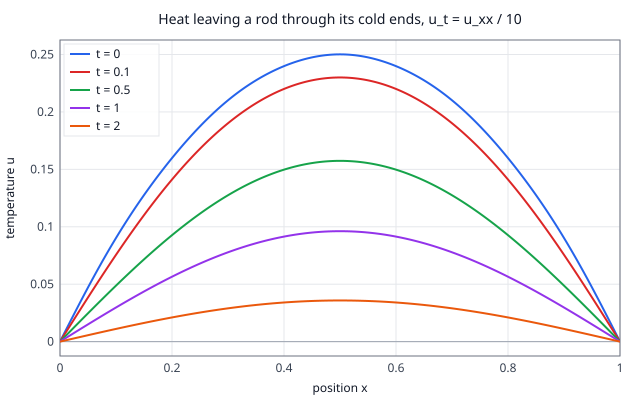

> `labels` (see `title`): A copy of plot p with a title or axis labels.

In [3]:
assume(n, integer, positive);
bn = 2*int(x*(1 - x)*sin(n*pi*x), x, 0, 1)
u = sum(bn*exp(-n^2*pi^2*t/10)*sin(n*pi*x), n, 1, 9);
p = plot(subs(u, t, 0), subs(u, t, 0.1), subs(u, t, 0.5), subs(u, t, 1), subs(u, t, 2), x, 0, 1);
p = legend(p, "t = 0", "t = 0.1", "t = 0.5", "t = 1", "t = 2");
labels(title(p, "Heat leaving a rod through its cold ends, u_t = u_xx / 10"), "position x", "temperature u")

Only odd $n$ appear ($b_n = 8/(\pi n)^3$), and the third mode decays $9$ times faster than the first. After a short
time only $b_1e^{-\pi^2t/10}\sin\pi x$ is left: whatever the start, the profile becomes a sine arch that shrinks
exponentially. **Heat smooths**: sharp features are high modes, and they disappear first. The same surface in 3D, with
time running back:

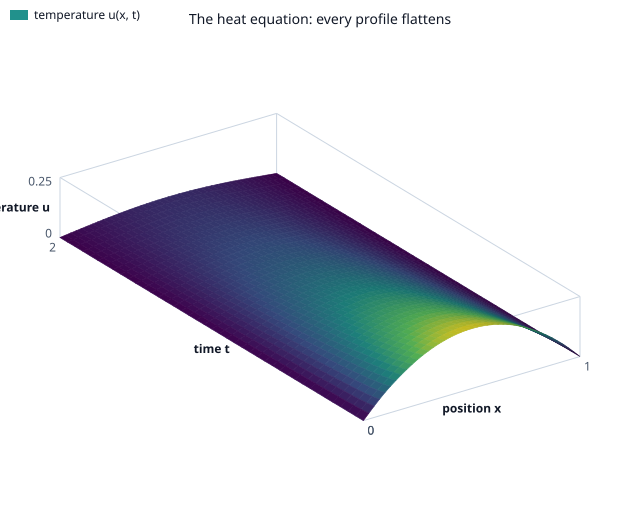

> `labels` (see `title`): A copy of plot p with a title or axis labels.

In [4]:
p = surface(x, t, u, x, 0, 1, t, 0, 2);
labels(title(legend(p, "temperature u(x, t)"), "The heat equation: every profile flattens"), "position x", "time t", "temperature u")

**Try this.** Start from a uniform temperature $f(x) = 1$ (the ends are suddenly cooled). Compute $b_n$. Why does the
series need many terms near $t = 0$ but very few later?

## 3. The wave equation: a plucked string

A string of length 1, fixed at both ends, obeys $u_{tt} = c^2u_{xx}$. Separation gives the same $X_n = \sin n\pi x$,
but now $T'' = -c^2n^2\pi^2T$: the modes **oscillate** instead of decaying,

$$u_n = \cos(cn\pi t)\sin(n\pi x)\quad\text{(released at rest)}.$$

Mode $n$ vibrates at $n$ times the frequency of mode 1: these are the **harmonics**, the overtones that give an
instrument its sound. Pluck the middle of the string to height 1 and release it ($c = 1$):

8*sin(pi*n/2)/(pi^2*n^2)

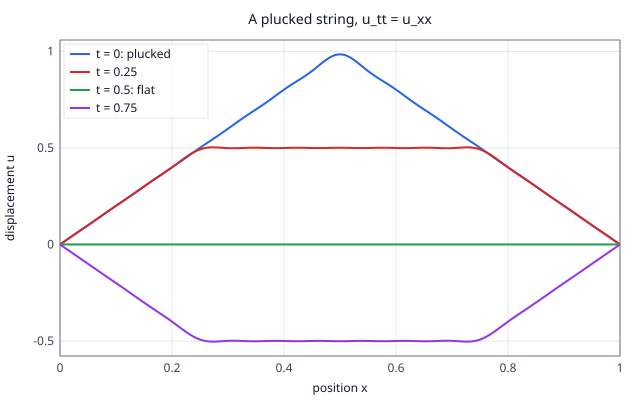

> `labels` (see `title`): A copy of plot p with a title or axis labels.

In [5]:
bp = 2*int((1 - 2*abs(x - 1/2))*sin(n*pi*x), x, 0, 1)
w = sum(bp*cos(n*pi*t)*sin(n*pi*x), n, 1, 25);
p = plot(subs(w, t, 0), subs(w, t, 0.25), subs(w, t, 0.5), subs(w, t, 0.75), x, 0, 1);
p = legend(p, "t = 0: plucked", "t = 0.25", "t = 0.5: flat", "t = 0.75");
labels(title(p, "A plucked string, u_tt = u_xx"), "position x", "displacement u")

$b_n = \frac{8\sin(n\pi/2)}{\pi^2n^2}$: the even harmonics are missing, because a string plucked at its middle cannot
start a mode with a node there. Guitarists pluck near the bridge to get a brighter sound with more harmonics. The
snapshots show the triangle splitting into two pieces that move apart, reflect at the ends and return: by d'Alembert,
every solution is $F(x - ct) + G(x + ct)$, two waves travelling in opposite directions. After time 2 the string is
back where it started; nothing decays, because there is no friction in the model.

**Try this.** Pluck at $x = 1/4$ instead: $f = 4x$ for $x \le 1/4$ and $\frac43(1 - x)$ after. Which harmonics are
missing now?

## 4. Laplace's equation: a steady temperature

A square metal plate $0 \le x, y \le 1$ has three edges at temperature 0 and the top edge held at
$u(x, 1) = x(1 - x)$. After a long time the temperature stops changing, $u_t = 0$, and the heat equation in two
dimensions becomes **Laplace's equation** $u_{xx} + u_{yy} = 0$. Separating $u = X(x)Y(y)$ with $X(0) = X(1) = 0$
gives $X_n = \sin n\pi x$ again, and $Y'' = n^2\pi^2Y$ with $Y(0) = 0$, so $Y_n = \sinh n\pi y$:

$$u(x, y) = \sum c_n\sinh(n\pi y)\sin(n\pi x), \qquad c_n = \frac{2}{\sinh n\pi}\int_0^1 x(1 - x)\sin(n\pi x)\,dx.$$

-4*((-1)^n-1)/(pi^3*n^3*sinh(pi*n))

0

> `simplify`: simplify(expr) writes expr in one fixed form: a fraction N/D of multiplied-out polynomials (in the symbols, constants and functions of expr) with common factors cancelled, square roots moved out of denominators, and sin^2 + cos^2 = 1 used in whichever direction is shorter.

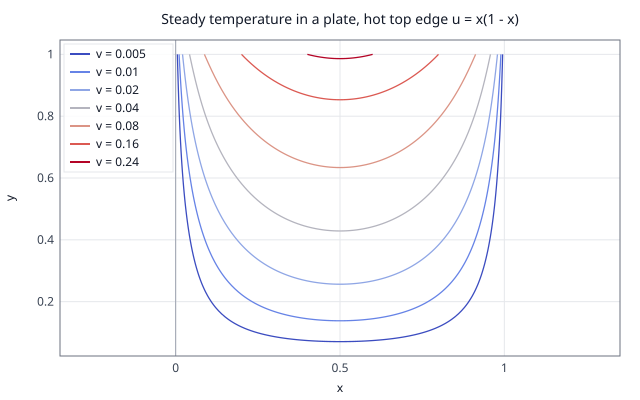

> `labels` (see `title`): A copy of plot p with a title or axis labels.

In [6]:
cn = 2*int(x*(1 - x)*sin(n*pi*x), x, 0, 1)/sinh(n*pi)
v = sum(cn*sinh(n*pi*y)*sin(n*pi*x), n, 1, 9);
simplify(laplacian(v, [x, y]))
p = contour(v, x, 0, 1, y, 0, 1, [0.005 0.01 0.02 0.04 0.08 0.16 0.24]);
labels(title(p, "Steady temperature in a plate, hot top edge u = x(1 - x)"), "x", "y")

The Laplacian of the answer is exactly 0. The temperature falls off quickly away from the hot edge: high modes decay
like $e^{-n\pi(1 - y)}$, so a few rows below the top only the first mode is visible. A solution of Laplace's equation
is **harmonic**: its value at any point is the average of its values on any circle around it, so it has no maxima or
minima inside the plate (the **maximum principle**). The hottest point is on the boundary.

**Try this.** Evaluate `eval(subs(subs(v, x, 1/2), y, 1/2))`, the temperature at the centre. Compare with the average
of the four edge temperatures at their midpoints.

In [7]:
forget(n);

## Summary

* Separation of variables: $u = X(x)T(t)$ turns a linear PDE into ODEs linked by a constant; the boundary conditions
  allow only certain modes.
* Heat equation: modes decay like $e^{-kn^2\pi^2t}$, high modes first; the solution is a sine series with decaying
  coefficients.
* Wave equation: modes oscillate at $n$ times the base frequency, the harmonics; plucking position decides which are
  present.
* Laplace's equation: steady states, $\sinh$ in one direction and $\sin$ in the other; harmonic functions take their
  extremes on the boundary.

This is the end of the differential equations path. From here, the [differential geometry](../differential-geometry/README.md)
and [general relativity](../general-relativity/README.md) paths use PDEs on curved spaces, and the
[chaos](../chaos/README.md) path shows what nonlinear systems can do.

## Exercises

1. **Heat, uniform start.** Solve $u_t = u_{xx}$ on $[0, 1]$ with zero ends and $u(x, 0) = 1$, up to $n = 9$. Plot
   $u(1/2, t)$ for $0 \le t \le 0.5$.
2. **Insulated rod.** With insulated ends the solution is $a_0/2 + \sum a_ne^{-kn^2\pi^2t}\cos n\pi x$. What
   temperature does the rod end at, if it starts at $u(x, 0) = x$?
3. **Struck string.** A string at rest is hit so that it starts with velocity $g(x) = \sin \pi x$ and zero
   displacement. Show that $u = \frac{1}{\pi}\sin(\pi t)\sin(\pi x)$ solves the wave equation with these conditions.
4. **Two dimensions.** Check with `laplacian` that $e^{x}\sin y$, $x^2 - y^2$ and $\log(x^2 + y^2)$ are harmonic.
5. **Musical fifths.** A string's second and third harmonics have frequency ratio $3:2$. If mode 1 of a guitar string is
   110 Hz (A), what are the frequencies of modes 2 to 5?

## Hints and answers

* **Section 1, Try this.** $X = C_1\cos\sqrt\lambda x + C_2\sin\sqrt\lambda x$; $X'(0) = 0$ gives $C_2 = 0$,
  $X'(1) = 0$ gives $\sqrt\lambda = n\pi$: modes $\cos n\pi x$ and the constant.
* **Section 2, Try this.** $b_n = \frac{2(1 - (-1)^n)}{n\pi}$, like $1/n$ because the start jumps at the ends; after a
  short time the factors $e^{-kn^2\pi^2t}$ kill all but the first few terms.
* **Section 3, Try this.** $b_n \propto \sin(n\pi/4)/n^2$: modes $4, 8, 12, \ldots$ are missing.
* **Section 4, Try this.** About $0.0513$. The four edge midpoints are $1/4, 0, 0, 0$, average $1/16 = 0.0625$:
  close, but the mean-value property holds for circles, not for four points.
* **Exercise 1.** $b_n = 4/(n\pi)$ for odd $n$; $u(1/2, t)$ starts at 1 and decays like $\frac4\pi e^{-\pi^2t}$.
* **Exercise 2.** $a_0/2 = \int_0^1 x\,dx = 1/2$: no heat leaves, so it ends at the average temperature.
* **Exercise 3.** $u_{tt} = -\pi^2u = u_{xx}$; $u(x, 0) = 0$ and $u_t(x, 0) = \sin\pi x$.
* **Exercise 4.** All three give 0 (the last for $(x, y) \ne (0, 0)$).
* **Exercise 5.** 220, 330, 440 and 550 Hz: the octave, the fifth above it, the next octave and a major third.

## Sources

1. J. Fourier, *Théorie analytique de la chaleur*, Firmin Didot (1822).
2. W. E. Boyce, R. C. DiPrima and D. B. Meade, *Elementary Differential Equations and Boundary Value Problems*, 11th
   ed., Wiley (2017), chapter 10.
3. W. A. Strauss, *Partial Differential Equations: An Introduction*, 2nd ed., Wiley (2008), chapters 2, 4 and 6.
4. J. le Rond d'Alembert, "Recherches sur la courbe que forme une corde tenduë mise en vibration", *Histoire de
   l'Académie royale des sciences et belles lettres de Berlin* 3 (1747) 214–219.